### REMOVE LATER

Here are the concepts that matter most for Task 2, each with a question to think about.

1. The knapsack problem

You have a backpack and 1001 items, each with a value and a weight. You choose which items to take. Normally there’s a weight limit, and the challenge is getting the most value without going over it.

In Task 2 there is no weight limit. Fitness is just the total value of what you take.

Think about: with no limit, what does the best possible solution look like? Is it hard to find? Your answer will frame everything you say in subtask 5.

2. Binary representation as “take it or leave it”

In Task 1 the bits encoded a number: position mattered, and the left bit was worth 32. Here, each bit is an independent yes/no for one item. Bit 500 means “item 500”, nothing more.

Think about: in Task 1, flipping the leftmost bit changed x by 32. What does flipping any single bit change in Task 2? This is why the knapsack fitness landscape is much “smoother” than Task 1’s polynomial.

3. Mutation rate scales with genome length

The expected number of flips per individual is n × PM. That’s the mean of a binomial distribution.

Task 1: 6 × 0.1 ≈ 0.6 flips, a gentle nudge.
Task 2: 1001 × 0.1 ≈ 100 flips per child, every generation.

The rule of thumb is PM ≈ 1/n, roughly one flip per child.

Think about: if a near-perfect individual (say 990 of 1001 bits set to 1) has 100 random bits flipped, does it usually get better or worse? What does that suggest about how close to the optimum your SGA will get with PM = 0.1? That’s a key “is this expected?” point for your report.

4. Selection pressure in fitness-proportional selection

Roulette selection works well when fitness values differ a lot relative to their size. In knapsack, a random individual already holds about half the items, so fitness values are large and close together. Something like 250,000 vs 252,000.

Think about: if every slice of the roulette wheel is almost the same size, is the best individual chosen much more often than the worst? What, then, is actually driving improvement in your SGA? Hint: look at survivor selection.

5. Elitism through (μ+λ) survivor selection

Your survivor selection keeps the best of parents plus offspring combined. That acts like a ratchet: the best can never get worse. Even if mutation wrecks most children, good parents just stay.

So weak parent selection, destructive mutation, and a ratchet together give slow but steady climbing. Expect a curve that keeps rising but probably doesn’t reach the true optimum in 1000 generations.

6. Exploration vs. exploitation

Exploration means trying new things: mutation and crossover.
Exploitation means focusing on what works: selection.

Task 2’s settings, with high PM and weak roulette pressure, lean heavily toward exploration. That’s a good lens for discussing your results.

7. Value-to-weight ratio, and what fitness ignores

The ratio value/weight measures how “efficient” an item is. Task 2’s fitness never looks at weight.

Think about: when you compare selected vs. unselected items in subtask 5, should their weights or ratios differ much? If you do see a difference, could it be explained by a correlation between value and weight in the data? That’s why the data analysis in subtask 1 matters.

Pick any of these and give me your answer. I’ll tell you if you’re on track before you write it into the report. Otherwise, a good next step is loading the data and checking the value/weight relationship.

### Setup

In [327]:
import random
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd

SEED = 22040 # Fixed number for the RNG to ensure reproducability.
random.seed(SEED)
np.random.seed(SEED)

### Functions from Task 1

In [328]:
# Parent Selection Function: 
# (Inputs: Individuals, Fitness values;
# Output: Parents (in random order, same number as individuals)). 
def parent_selection( individuals: list[list[int]], fitness_values: list[float] ) -> list[list[int]]:
    """Perform fitness-proportional parent selection such that more fit parents have a higher probability to be selected. """
    fitness = np.array(fitness_values, dtype=float)
    probs = fitness / fitness.sum()
    idx = np.random.choice(len(individuals), size=len(individuals), replace=True, p=probs)
    return [individuals[i] for i in idx]


# Recombination (Crossover) Function:
# (Inputs: Parents, Crossover Probability;
# Outputs: Offspring (pre-Mutation)). 
def one_point_crossover( parents: list[list[int]], crossover_prob: float ) -> list[list[int]]:
    """Performs 1-point crossover and generates for parents 1 & 2, parents 3 & 4 etc. offspring. """
    offsprings = []
    for i in range(0, len(parents)-1, 2):
        parent1, parent2 = parents[i], parents[i+1]
        offspring1, offspring2 = parent1.copy(), parent2.copy()

        alpha = np.random.uniform(0, 1)
        if alpha <= crossover_prob:
            cpoint = random.randint(1, len(parent1) - 1)
            offspring1 = parent1[:cpoint] + parent2[cpoint:]
            offspring2 = parent2[:cpoint] + parent1[cpoint:]

        offsprings.append(offspring1)
        offsprings.append(offspring2)

    if len(parents) % 2 == 1:
        offsprings.append(parents[-1].copy())

    return offsprings


# Mutation Function:
# (Inputs: Individuals, Mutation Probability $P_M$;
#  Outputs: Offspring (mutated)). 
def mutation( individuals: list[list[int]], mutation_prob: float ) -> list[list[int]]:
    """Performs bitflip mutation for each bit / gene in each individual with mutation probability of P_M."""
    mutated = []
    for individual in individuals:
        offspring = individual.copy()
        for i in range(len(offspring)):
            if np.random.uniform(0, 1) <= mutation_prob:
                offspring[i] = 1 - individual[i] # flipping each bit
            else:
                continue
        mutated.append(offspring)
    return mutated


# Survivor Selection Function:
# (Inputs: Individuals, Offspring, Fitness Individuals, Fitness Offspring;
# Outputs: (New) population). 
def survivor_selection( individuals: list[list[int]], offspring: list[list[int]],
                        fitness_individuals: list[float], fitness_offspring: list[float]) -> list[list[int]]:
    """Selects survivors based on the highest fitness values from the pooled population individuals and offspring. """
    combined = individuals + offspring
    combined_fitness = fitness_individuals + fitness_offspring
    fitness_ordered = np.argsort(combined_fitness)[::-1]

    return  [combined[i] for i in fitness_ordered[:len(individuals)]] 

# Task 2

## Subtask 1
Load the data set data 1001.csv. The first column contains the values for
each item - save them as a list item values - and the second column con-
tains the weights of each item - save them as a list item weights. State the
size of the data set and analyze the values and the weights that the items
take and any possible relationship between the values and the weights.
Comment on your findings.

**Note on outlier:** (value: *3300*, weight: *100000*) is an extreme outlier. Its weight is roughly 5× larger than any other item and it lies far from the linear value-weight trend followed by the rest of the data. To keep the plots readable, it is excluded from the **scatter plot** and **histograms** below; summary statistics are reported with the outlier. The item is **kept in the data set for the GA**, since it is a valid item in the knapsack problem.

### Analyzing data

#### Reading data
**NOTE:** also setting up data_31 for testing

In [330]:
df = pd.read_csv('../data/data_1001.csv')

item_values = df["Value"].to_numpy()
item_weights = df["Weight"].to_numpy()

# without the outlier
df_no_outlier = df[df["Weight"] <= 50000]
item_values_no_outlier = df_no_outlier["Value"].to_numpy()
item_weights_no_outlier = df_no_outlier["Weight"].to_numpy()


test_df = pd.read_csv('../data/data_31.csv')
test_item_values = test_df["Value"].to_numpy()
test_item_weights = test_df["Weight"].to_numpy()


#### lenght of data

In [331]:
print("Lenght with all entries")
print(f"Length of item_values: {len(item_values)}")
print(f"Length of item_weights: {len(item_weights)}")

print("\nLenght without outlier")
print(f"Length of item_values_no_outlier: {len(item_values_no_outlier)}")
print(f"Length of item_weights_no_outlier: {len(item_weights_no_outlier)}")


# RANDOM STUFF (REMOVE LATER)
#print("Shape of 'data_1001.csv'")
#print(f"Number of columns: {data_frame.shape[1]}")
#print(f" {'Column 1:':>10} {data_frame.columns[0]}")
#print(f" {'Column 2:':>10} {data_frame.columns[1]}")

#print("Printing head of dataframe")
#print(data_frame.head())

# plt.hist(data_a, bins=20, alpha=0.5, label='A')
# plt.hist(data_b, bins=20, alpha=0.5, label='B')
# plt.legend()
# plt.show()

#print(df[df["Weight"] >= 50000])


Lenght with all entries
Length of item_values: 1001
Length of item_weights: 1001

Lenght without outlier
Length of item_values_no_outlier: 1000
Length of item_weights_no_outlier: 1000


#### Describing the data (value and weight)

In [332]:
print(df.describe())

              Value         Weight
count   1001.000000    1001.000000
mean    5762.173826   10134.013986
std     5770.419772    6386.142389
min    -4299.000000       1.000000
25%      940.000000    5245.000000
50%     5819.000000   10133.000000
75%    10596.000000   15012.000000
max    17195.000000  100000.000000


#### Distribution of item_values

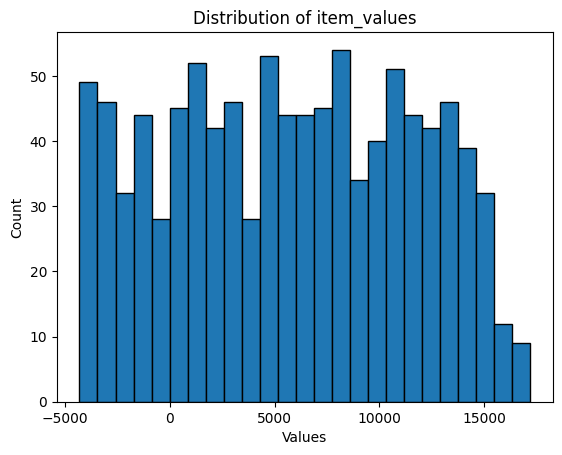

In [333]:
plt.hist(item_values, bins=25, edgecolor='black')
plt.xlabel('Values')
plt.ylabel('Count')
plt.title('Distribution of item_values')
plt.show()

#### Distribution of item_weights

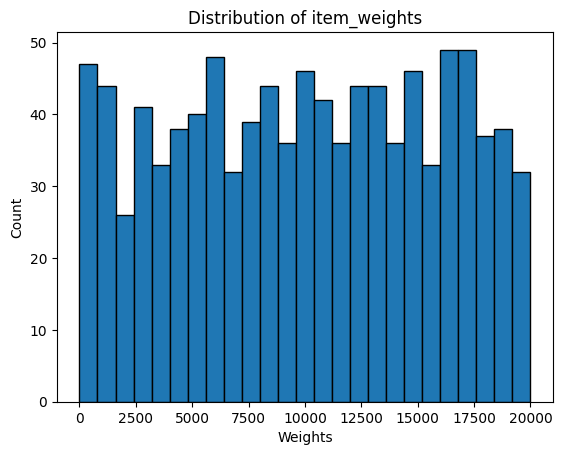

In [334]:
plt.hist(item_weights_no_outlier, bins=25, edgecolor='black')
#plt.xlim(right=30000)
plt.xlabel('Weights')
plt.ylabel('Count')
plt.title('Distribution of item_weights')
plt.show()

#### Scatter plot of value against weight.

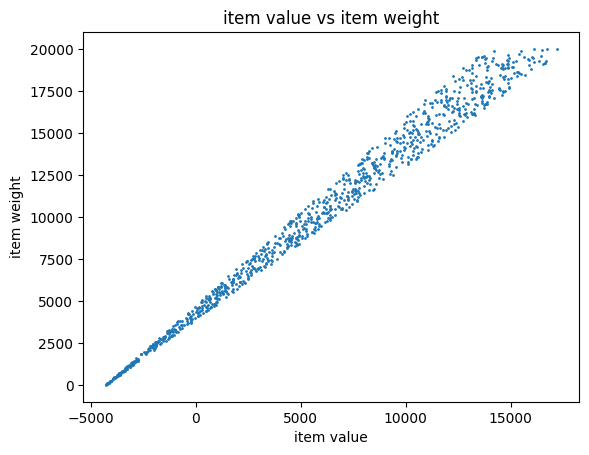

In [335]:
plt.scatter(item_values_no_outlier, item_weights_no_outlier, s=1)
plt.xlabel('item value')
plt.ylabel('item weight')
plt.title('item value vs item weight')
plt.show()


#### Maximum fitness
Summing the value of all items, where value >= 0

In [336]:
postive_values_only = df[df["Value"] >= 0]

print("Number of items, where value >= 0", postive_values_only.shape[0])

sum_of_values = postive_values_only.Value.sum()

print("Maximum fitness: ", sum_of_values)

Number of items, where value >= 0 802
Maximum fitness:  6231819


### What can we extract from the information above?

**Dataset size:** the data set contains 1001 items, each with a value and weight.

**Value and weight distributions:** Item values range from -4299 to 17,195 (mean = 5762), and weights range from 1 to 100,000 (mean = 10134). Notably, some item values are negative.

**Outlier:** item with (value: [3300], weight: [100,000]) is an extreme outlier, with a weight far above all other items and well off the trend followed by the rest of the data. It is excluded from the plots for readability but kept in the data set for the GA.

**Relationship between the values and weights:** The scatter plot shows a strong linear relationship: heavier items tend to be more valuable.

**Values being able to be negative:** another interesting thing to keep in mind, after looking at the data is that item values can be negative (ranging from -4299 to 17195).

**Maximum possible fitness:** Since Task 2 has no weight limit, the optimal solution is to select all items with positive values and exclude all other. So we can find the maximum possible fitness by summing the value of all items with positive values, that turns out to be **maximum possible fitness = 6231819**. This lets us measure how close the GA gets to the true optimum.

**Effect of negative values on selection:** the problem that may come up is that if an individuals fitness is negative that breaks *np.random.choice*. But for the most part we should be safe since the mean item value is around 5762.

## Subtask 2
Write a NEW initialization function that creates a binary list that is
suitable to represent this problem. As before: (Inputs: Population Size,
Output: Individuals).

In [337]:
# import variables
# item_values: list of all values
# item_weights: list of all weights

def initialization_population( pop_size: int, num_bits: int=4  ) -> list[list[int]]:
    """
    This function creates the individuals for the population, each having num_bits genes. 

    Returns:
      A list of `pop_size` individuals, each a list of `num_bits` ints (0 or 1).
    
    Example:
        >>> initialization_population(pop_size=3, num_bits=4)
        [[0, 1, 1, 0], [1, 0, 0, 1], [1, 1, 0, 0]]
    """
    population = []
    for _ in range(pop_size):
        population.append(np.random.randint(0, 2, num_bits, int).tolist())
    return population

#### Testing subtask 2

In [338]:
def test_initialization_population():
    population_size = 5
    gene_len        = len(item_values)

    population = initialization_population(
        pop_size=population_size,
        num_bits=gene_len)

    print("Testing population size: expected 5")
    if len(population) == 5:
        print("CORRECT")
        print("population size: ", len(population))
    else:
        print("INCORRECT")

    print()

    print("Testing individual lenght: expected 1001")
    individual_1 = population[0]
    if len(individual_1) == 1001:
        print("CORRECT")
        print("individual size: ", len(individual_1))
    else:
        print("INCORRECT")
        print("individual size: ", len(individual_1))

    print()

    print("Printing Individuals")
    for num, individual in enumerate(population):
        print(f"{num + 1}: {individual}")

test_initialization_population()

Testing population size: expected 5
CORRECT
population size:  5

Testing individual lenght: expected 1001
CORRECT
individual size:  1001

Printing Individuals
1: [1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 

## Subtask 3
Since the aim of knapsack is to maximize the value of items selected (0 -
not selected, 1 - selected), write a NEW fitness function that sums the
value of all items selected.

**NOTE:** The fitness function ignores weight completly

In [339]:
# using dotproduct to find fitness
def fitness (individuals: list[list[int]], values: list[int]) -> list[int]:
    """
    Calculate the fitness of each individual in the population.

    An individual's fitness is the total value of the items it selects,
    computed as the dot product of its genes and the item values.

    Args:
        individuals: list of individuals in the population
        values: list of item values
    
    Returns:
        A list with one fitness score per individual.
    
    Example:
        >>> fitness([[0,1,1],[1,1,0]], [200,100,50])
        [150, 300]
    """
    value_list = [None] * len(individuals)

    for index in range(len(individuals)):
        value_list[index] = np.dot(individuals[index], values)
    
    return value_list

#### Testing fitness function

In [340]:
def test_fitness():
    pop_size = 10
    gene_len = len(test_item_values)

    population = initialization_population(pop_size, gene_len)
    fitness_values = fitness(population, test_item_values)
    
    print(f"Individual{"":<1} | Fitness{"":<7} |")
    for index in range(len(population)):
        print("-" * 12 + "|" + "-" * 16 + "|")
        print(f"{index:<11} | {fitness_values[index]:<15}|")


test_fitness()    

Individual  | Fitness        |
------------|----------------|
0           | 689069         |
------------|----------------|
1           | 695576         |
------------|----------------|
2           | 686777         |
------------|----------------|
3           | 539058         |
------------|----------------|
4           | 693811         |
------------|----------------|
5           | 461810         |
------------|----------------|
6           | 537087         |
------------|----------------|
7           | 766575         |
------------|----------------|
8           | 384329         |
------------|----------------|
9           | 995807         |


## Subtask4
Run the SGA with the new initialization and new fitness function, with
population size 30, number of iterations 1000, PC = 0.9 and PM = 0.1.
State the average fitness of the final population and the best fitness in the
final population. (Note: Since the SGA is heuristic, different groups may
end up with different best solutions and best fitness values).

In [341]:
def simple_genetic_algorithm(
    population_size, number_iter,
    crossover_prob, mutation_prob,
    value_list
    ) -> tuple[list[float], list[float], list[list[int], list[float]]]:
    """
    SGA for Task 2

    Returns:
        A list with 4 items.
        * avg_fitness_data
        * best_fitness_data
        * population
        * fitness_values
    """
    # To keep track of avg and best fitness across iterations
    avg_fitness_data, best_fitness_data = [], []
    # curr_avg_fit, curr_best_fit = 0.0, 0.0
    
    gene_len = len(value_list)
    population = initialization_population(
        pop_size=population_size,
        num_bits=gene_len
    )

    for _ in range(number_iter):
        fitness_values = fitness(population, value_list)


        new_avg_fitness = np.mean(fitness_values)
        avg_fitness_data.append(new_avg_fitness)

        new_best_fitness = np.max(fitness_values)
        best_fitness_data.append(new_best_fitness)

        # if new_best_fitness > curr_best_fit:
        #    curr_best_fit = new_best_fitness

        parents = parent_selection(population, fitness_values)

        offspring = one_point_crossover(parents, crossover_prob)
        offspring = mutation(offspring, mutation_prob)
        offspring_fitness_values = fitness(offspring, value_list)

        survivors = survivor_selection(
            population,
            offspring,
            fitness_values,
            offspring_fitness_values
        )
        population = survivors

    return avg_fitness_data, best_fitness_data, population, fitness(population, value_list)

### Testing SGA

Average fitness of final population: 3413941.566666667
Best fitness of final population: 3480661


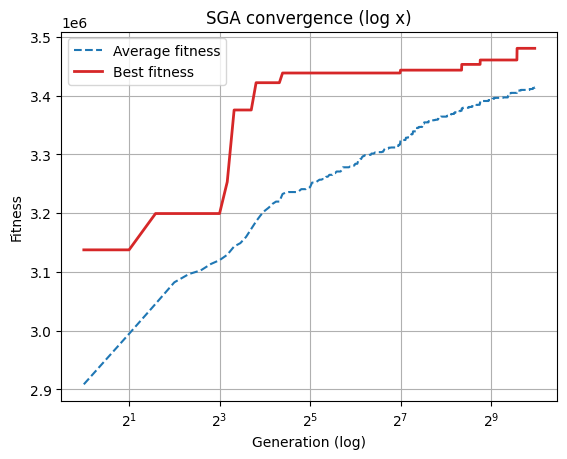

In [348]:
def plot_fitness_data( avg_fitness_data: list[float], best_fitness_data: list[float], num_iter: int ):
    gens = range(1, num_iter + 1)

    plt.plot(gens, avg_fitness_data, color="tab:blue", linestyle="--", label="Average fitness")
    plt.plot(gens, best_fitness_data, color="tab:red",  linestyle="-",  linewidth=2, label="Best fitness")
    plt.xscale("log", base=2)
    plt.xlabel("Generation (log)")
    plt.ylabel("Fitness")
    plt.title("SGA convergence (log x)")
    plt.legend()
    plt.grid(True)
    plt.show()


def test_SGA(
    pop_size            = 10,
    number_iternations  = 100,
    crossover_prob      = 0.9,
    mutation_prob       = 0.1,
    value_list          = None):
    """
    Test SGA
    """
    if value_list is None:
        print("value_list missing")
        return None
    
    report = simple_genetic_algorithm(
        pop_size,
        number_iternations,
        crossover_prob,
        mutation_prob,
        value_list
    )
    avg_fitness_data   = report[0]
    best_fitness_data  = report[1]
    population         = report[2]
    population_fitness = report[3]

    print(f"Average fitness of final population: {avg_fitness_data[number_iternations-1]}")
    print(f"Best fitness of final population: {best_fitness_data[number_iternations-1]}")

    plot_fitness_data( avg_fitness_data, best_fitness_data, number_iternations)

# test with data_31.csv
#test_SGA(30, 1000, 0.9, 0.1, test_item_values)

# test with data_1001.csv
test_SGA(30, 1000, 0.5, 0.4, item_values)

## SubTask5
The best solution found is harder to interpret than before (as it cannot
just be converted into a single integer). Thus, describe the solution found
based on the fitness, number of items selected, and the min, mean, max of
the values, of the weights and of the ratio of value-to-weight of the selected
items. Compare this with the same information on the items that were
not selected. Comment on your findings and whether the results are as
expected. Why / why not?